# Tarea 5 - Diplomado ML Facultad de Ingeniería

> Edgar Ulises Moreno Chalico
>
> 318192950

1. Aplica Naive Bayes y Máquinas de Soporte Vectorial (aplica kernel polinomial) al dataset del Titanic y compara qué características destacan estos dos modelos con relación a los cuatro modelos vistos en clase.

2. Aplica RandomForest en su versión de regresión al dataset de las casas de Taiwán. ¿Se logra un r2 mayor al 70%?

3. Aplica árboles de decisión al dataset car_evaluation.csv
Genera el árbol con plot tree y muestra la gráfica de feature importance y permutation importance

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Actividad 1

Mejores parámetros SVM poly: {'svc__C': 1, 'svc__coef0': 1, 'svc__degree': 2, 'svc__gamma': 0.1}
Mejor accuracy SVM poly (CV): 82.34%
=> Accuracy (%)
                     Train   Test
Naive Bayes          78.33  80.97
SVM poly             83.31  83.21
Regresión logística  79.45  80.60
KNN                  86.36  83.96
Árbol de decisión    83.63  80.22
Random Forest        98.72  81.72
=> Permutation importance (caída de accuracy en test)
            Naive Bayes  SVM poly  Regresión logística    KNN  \
Pclass            0.010     0.035                0.063  0.066   
Age               0.000     0.034                0.020  0.042   
SibSp             0.022     0.028                0.013  0.043   
Parch             0.010     0.033               -0.004  0.022   
Fare              0.030     0.005               -0.000  0.040   
Sex_male          0.226     0.256                0.219  0.198   
Embarked_Q       -0.001     0.008               -0.000  0.012   
Embarked_S        0.029     0.009     

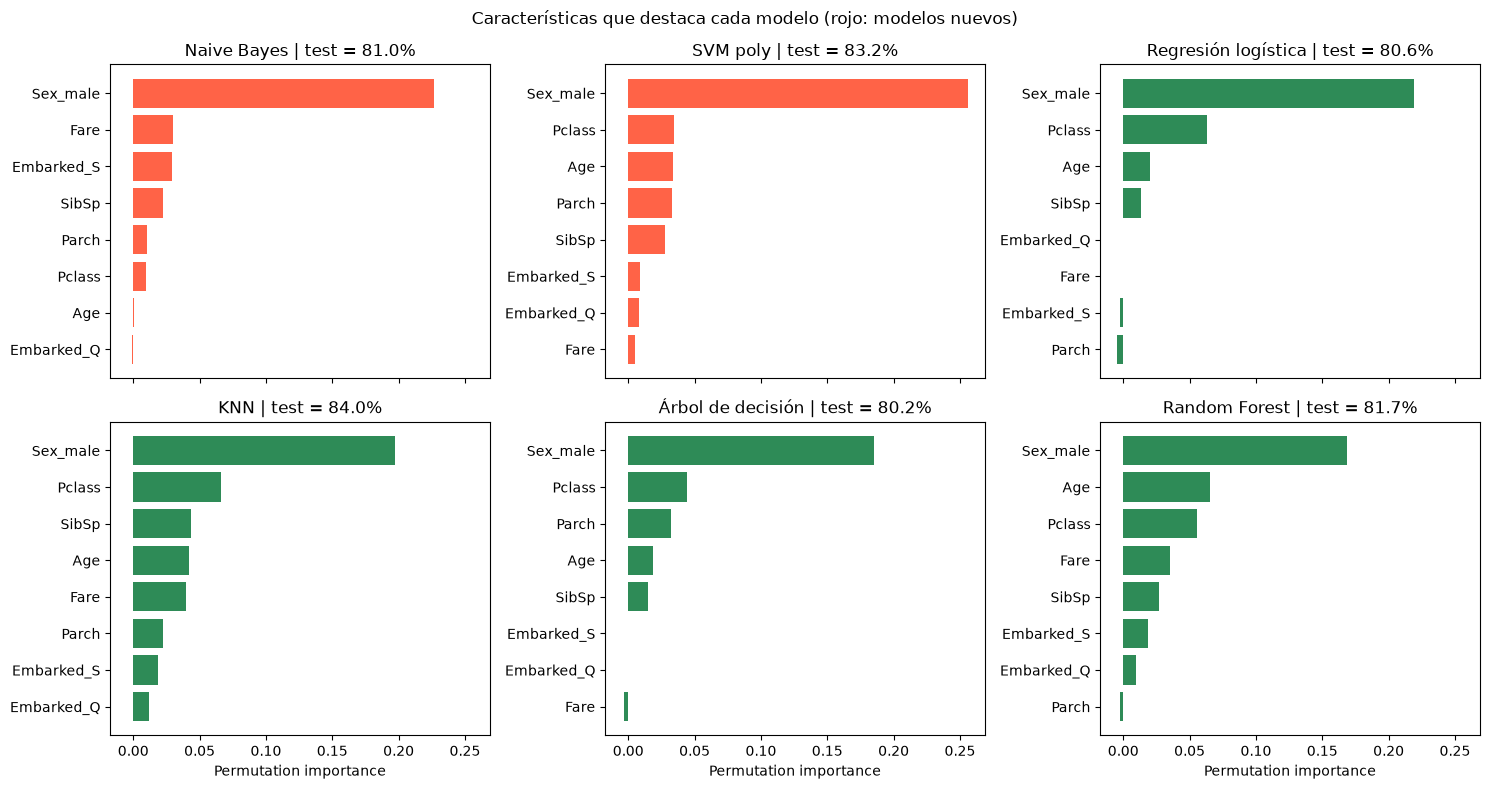

In [2]:
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import permutation_importance

df = pd.read_csv("./titanicData.csv")

# Borrar variables que no se usarán
df = df.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"])

# Llenado de valores incompletos
df["Age"] = df["Age"].fillna(df["Age"].mean())
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

# drop_first para que "Sex" quede en una sola columna (Sex_male) y su importancia no se reparta
X = pd.get_dummies(df.drop(columns=["Survived"]), columns=["Sex", "Embarked"], drop_first=True, dtype=int)
y = df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)

# SVM con kernel polinomial
grid = GridSearchCV(make_pipeline(StandardScaler(), SVC(kernel="poly")), {
    "svc__C": [0.1, 1, 10],
    "svc__degree": [2, 3],
    "svc__gamma": ["scale", 0.1],
    "svc__coef0": [0, 1],
}, cv=5, scoring="accuracy", n_jobs=-1)
grid.fit(X_train, y_train)

print(f"Mejores parámetros SVM poly: {grid.best_params_}")
print(f"Mejor accuracy SVM poly (CV): {grid.best_score_ * 100:.2f}%")

models = {
    "Naive Bayes": make_pipeline(StandardScaler(), GaussianNB()),
    "SVM poly": grid.best_estimator_,
    "Regresión logística": make_pipeline(StandardScaler(), LogisticRegression(solver="liblinear")),
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier()),
    "Árbol de decisión": DecisionTreeClassifier(max_depth=4, random_state=0),
    "Random Forest": RandomForestClassifier(random_state=0),
}

scores = {}
importances = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    scores[name] = {
        "Train": model.score(X_train, y_train) * 100,
        "Test": model.score(X_test, y_test) * 100,
    }
    # Permutation importance: funciona igual para todos los modelos (NB y SVM no tienen feature_importances_)
    result = permutation_importance(model, X_test, y_test, n_repeats=30, random_state=0, n_jobs=-1)
    importances[name] = pd.Series(result.importances_mean, index=X.columns)

print("=> Accuracy (%)")
print(pd.DataFrame(scores).T.round(2))

importances = pd.DataFrame(importances)
print("=> Permutation importance (caída de accuracy en test)")
print(importances.round(3))

print("=> Top 3 características por modelo")
for name in importances.columns:
    print(f"{name}: {importances[name].sort_values(ascending=False).index[:3].tolist()}")

fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True)

for ax, name in zip(axes.ravel(), importances.columns):
    imp = importances[name].sort_values()
    ax.barh(imp.index, imp.values, color="tomato" if name in ["Naive Bayes", "SVM poly"] else "seagreen")
    ax.set_title(f"{name} | test = {scores[name]['Test']:.1f}%")

for ax in axes[1]:
    ax.set_xlabel("Permutation importance")

plt.suptitle("Características que destaca cada modelo (rojo: modelos nuevos)")
plt.tight_layout()
plt.show()

Como Naive Bayes y SVM no tienen `feature_importances_`, se usó **permutation importance** en el conjunto de prueba para comparar a los seis modelos con la misma medida. Los cuatro modelos de clase que se tomaron como referencia son regresión logística, KNN, árbol de decisión y Random Forest.

- **Todos los modelos coinciden en que `Sex` es la característica más importante**: si se revuelve, el accuracy cae entre 17 y 26 puntos. SVM poly (0.256) y Naive Bayes (0.226) son los que más dependen de ella.
- **SVM poly** destaca lo mismo que la regresión logística (`Sex`, `Pclass`, `Age`), pero reparte más importancia entre `Age`, `SibSp` y `Parch`. El kernel polinomial capta interacciones (por ejemplo edad × clase) que el modelo lineal no ve. Es el segundo mejor en test (83.2%) y no se sobreajusta (train ≈ test).
- **Naive Bayes** es el más distinto: casi no usa `Pclass` (0.010) ni `Age` (0.000), y en su lugar usa `Fare` y `Embarked_S`. Como supone que las variables son independientes, trata `Fare` como sustituto de la clase (están muy correlacionadas) y le da a `Pclass` muy poco peso. Su accuracy (81%) es parecido al de la regresión logística.
- En los modelos de clase, `Pclass` siempre queda en el top 3. Random Forest le da más peso a `Age` y `Fare` (variables continuas con muchos cortes posibles), y es el que más se sobreajusta (98.7% train vs 81.7% test).

## Actividad 2

(414, 8)
Mejores parámetros: {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'n_estimators': 200}
Mejor r2 (CV): 73.24%
r2 con parámetros por defecto (CV): 70.63%
Fold 1 | r2 = 74.40%
Fold 2 | r2 = 81.64%
Fold 3 | r2 = 59.98%
Fold 4 | r2 = 78.52%
Fold 5 | r2 = 82.77%
Fold 6 | r2 = 81.08%
Fold 7 | r2 = 86.68%
Fold 8 | r2 = 39.41%
Fold 9 | r2 = 77.90%
Fold 10 | r2 = 70.04%
r2 promedio: 73.24% (± 13.36)
MAE = 13409.43


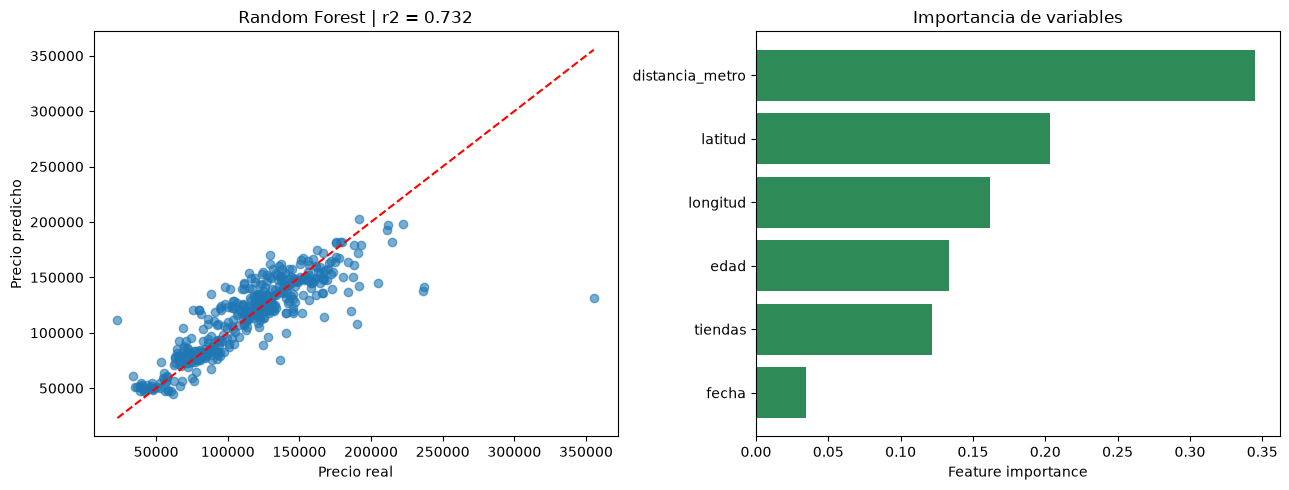

In [3]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, KFold, cross_val_score, cross_val_predict
from sklearn.metrics import mean_absolute_error

df = pd.read_csv("./casas_taiwan.csv")
print(df.shape)

X = df.drop(columns=["No", "precio"])
y = df["precio"]

folds = KFold(n_splits=10, shuffle=True, random_state=0)

# Random Forest no necesita escalar las variables
grid = GridSearchCV(RandomForestRegressor(random_state=0), {
    "n_estimators": [200],
    "max_features": [1.0, 0.5, "sqrt"],
    "min_samples_leaf": [1, 2, 4],
    "max_depth": [None, 10],
}, cv=folds, scoring="r2", n_jobs=-1)
grid.fit(X, y)

print(f"Mejores parámetros: {grid.best_params_}")
print(f"Mejor r2 (CV): {grid.best_score_ * 100:.2f}%")

final_model = grid.best_estimator_

# r2 con parámetros por defecto, como referencia
r2_default = cross_val_score(RandomForestRegressor(random_state=0), X, y, cv=folds, scoring="r2", n_jobs=-1)
print(f"r2 con parámetros por defecto (CV): {r2_default.mean() * 100:.2f}%")

scores = cross_val_score(final_model, X, y, cv=folds, scoring="r2", n_jobs=-1)
for i, score in enumerate(scores):
    print(f"Fold {i + 1} | r2 = {score * 100:.2f}%")
print(f"r2 promedio: {scores.mean() * 100:.2f}% (± {scores.std() * 100:.2f})")

y_pred_cv = cross_val_predict(final_model, X, y, cv=folds, n_jobs=-1)
print(f"MAE = {mean_absolute_error(y, y_pred_cv):.2f}")

final_model.fit(X, y)
feature_imp = pd.Series(final_model.feature_importances_, index=X.columns).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

limits = [min(y.min(), y_pred_cv.min()), max(y.max(), y_pred_cv.max())]
axes[0].scatter(y, y_pred_cv, alpha=0.6)
axes[0].plot(limits, limits, "r--")
axes[0].set_xlabel("Precio real")
axes[0].set_ylabel("Precio predicho")
axes[0].set_title(f"Random Forest | r2 = {scores.mean():.3f}")

axes[1].barh(feature_imp.index, feature_imp.values, color="seagreen")
axes[1].set_xlabel("Feature importance")
axes[1].set_title("Importancia de variables")

plt.tight_layout()
plt.show()

**Sí se logra un r2 mayor al 70%.** Con GridSearchCV (10 folds) el Random Forest alcanza **r2 de aprox. 73.2%**. Los mejores parámetros limitan la profundidad (`max_depth=10`, `min_samples_leaf=2`, `max_features="sqrt"`), lo que reduce el sobreajuste.

El r2 cambia mucho entre folds (de 39% a 87%). Los folds bajos contienen casas con precios atípicos muy altos que el bosque no puede predecir, porque solo promedia valores que ya vio. Las variables más importantes son `distancia_metro`, `latitud`/`longitud` y `edad`, es decir, la ubicación.

## Actividad 3

In [4]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import OrdinalEncoder
from sklearn.inspection import permutation_importance
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# car_evaluation.csv (en este directorio se llama car.csv)
df = pd.read_csv("./car.csv").iloc[:, 1:]
print(df.shape)
print(df["Class"].value_counts())

X = df.drop(columns=["Class"]).astype(str)
y = df["Class"]

# Las variables son ordinales, se codifican respetando su orden para que los cortes del árbol sean legibles
orden = [
    ["low", "med", "high", "vhigh"],  # buying
    ["low", "med", "high", "vhigh"],  # maint
    ["2", "3", "4", "5more"],  # doors
    ["2", "4", "more"],  # persons
    ["small", "med", "big"],  # lug_boots
    ["low", "med", "high"],  # safety
]
encoder = OrdinalEncoder(categories=orden)
X = pd.DataFrame(encoder.fit_transform(X), columns=X.columns)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)

grid = GridSearchCV(DecisionTreeClassifier(random_state=0), {
    "criterion": ["gini", "entropy"],
    "max_depth": [3, 5, 7, 9, None],
    "min_samples_leaf": [1, 2, 5],
}, cv=5, scoring="accuracy", n_jobs=-1)
grid.fit(X_train, y_train)

model = grid.best_estimator_

print(f"Mejores parámetros: {grid.best_params_}")
print(f"Mejor accuracy (CV): {grid.best_score_ * 100:.2f}%")
print(f"Train accuracy: {model.score(X_train, y_train) * 100:.2f}%")
print(f"Test accuracy: {model.score(X_test, y_test) * 100:.2f}%")
print(f"Profundidad: {model.get_depth()} | Hojas: {model.get_n_leaves()}")

y_pred_test = model.predict(X_test)
print(classification_report(y_test, y_pred_test))

(1728, 7)
Class
unacc    1210
acc       384
good       69
vgood      65
Name: count, dtype: int64
Mejores parámetros: {'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 1}
Mejor accuracy (CV): 98.10%
Train accuracy: 100.00%
Test accuracy: 96.53%
Profundidad: 12 | Hojas: 62
              precision    recall  f1-score   support

         acc       0.92      0.96      0.94       115
        good       0.86      0.86      0.86        21
       unacc       0.99      0.98      0.98       363
       vgood       0.89      0.85      0.87        20

    accuracy                           0.97       519
   macro avg       0.92      0.91      0.91       519
weighted avg       0.97      0.97      0.97       519



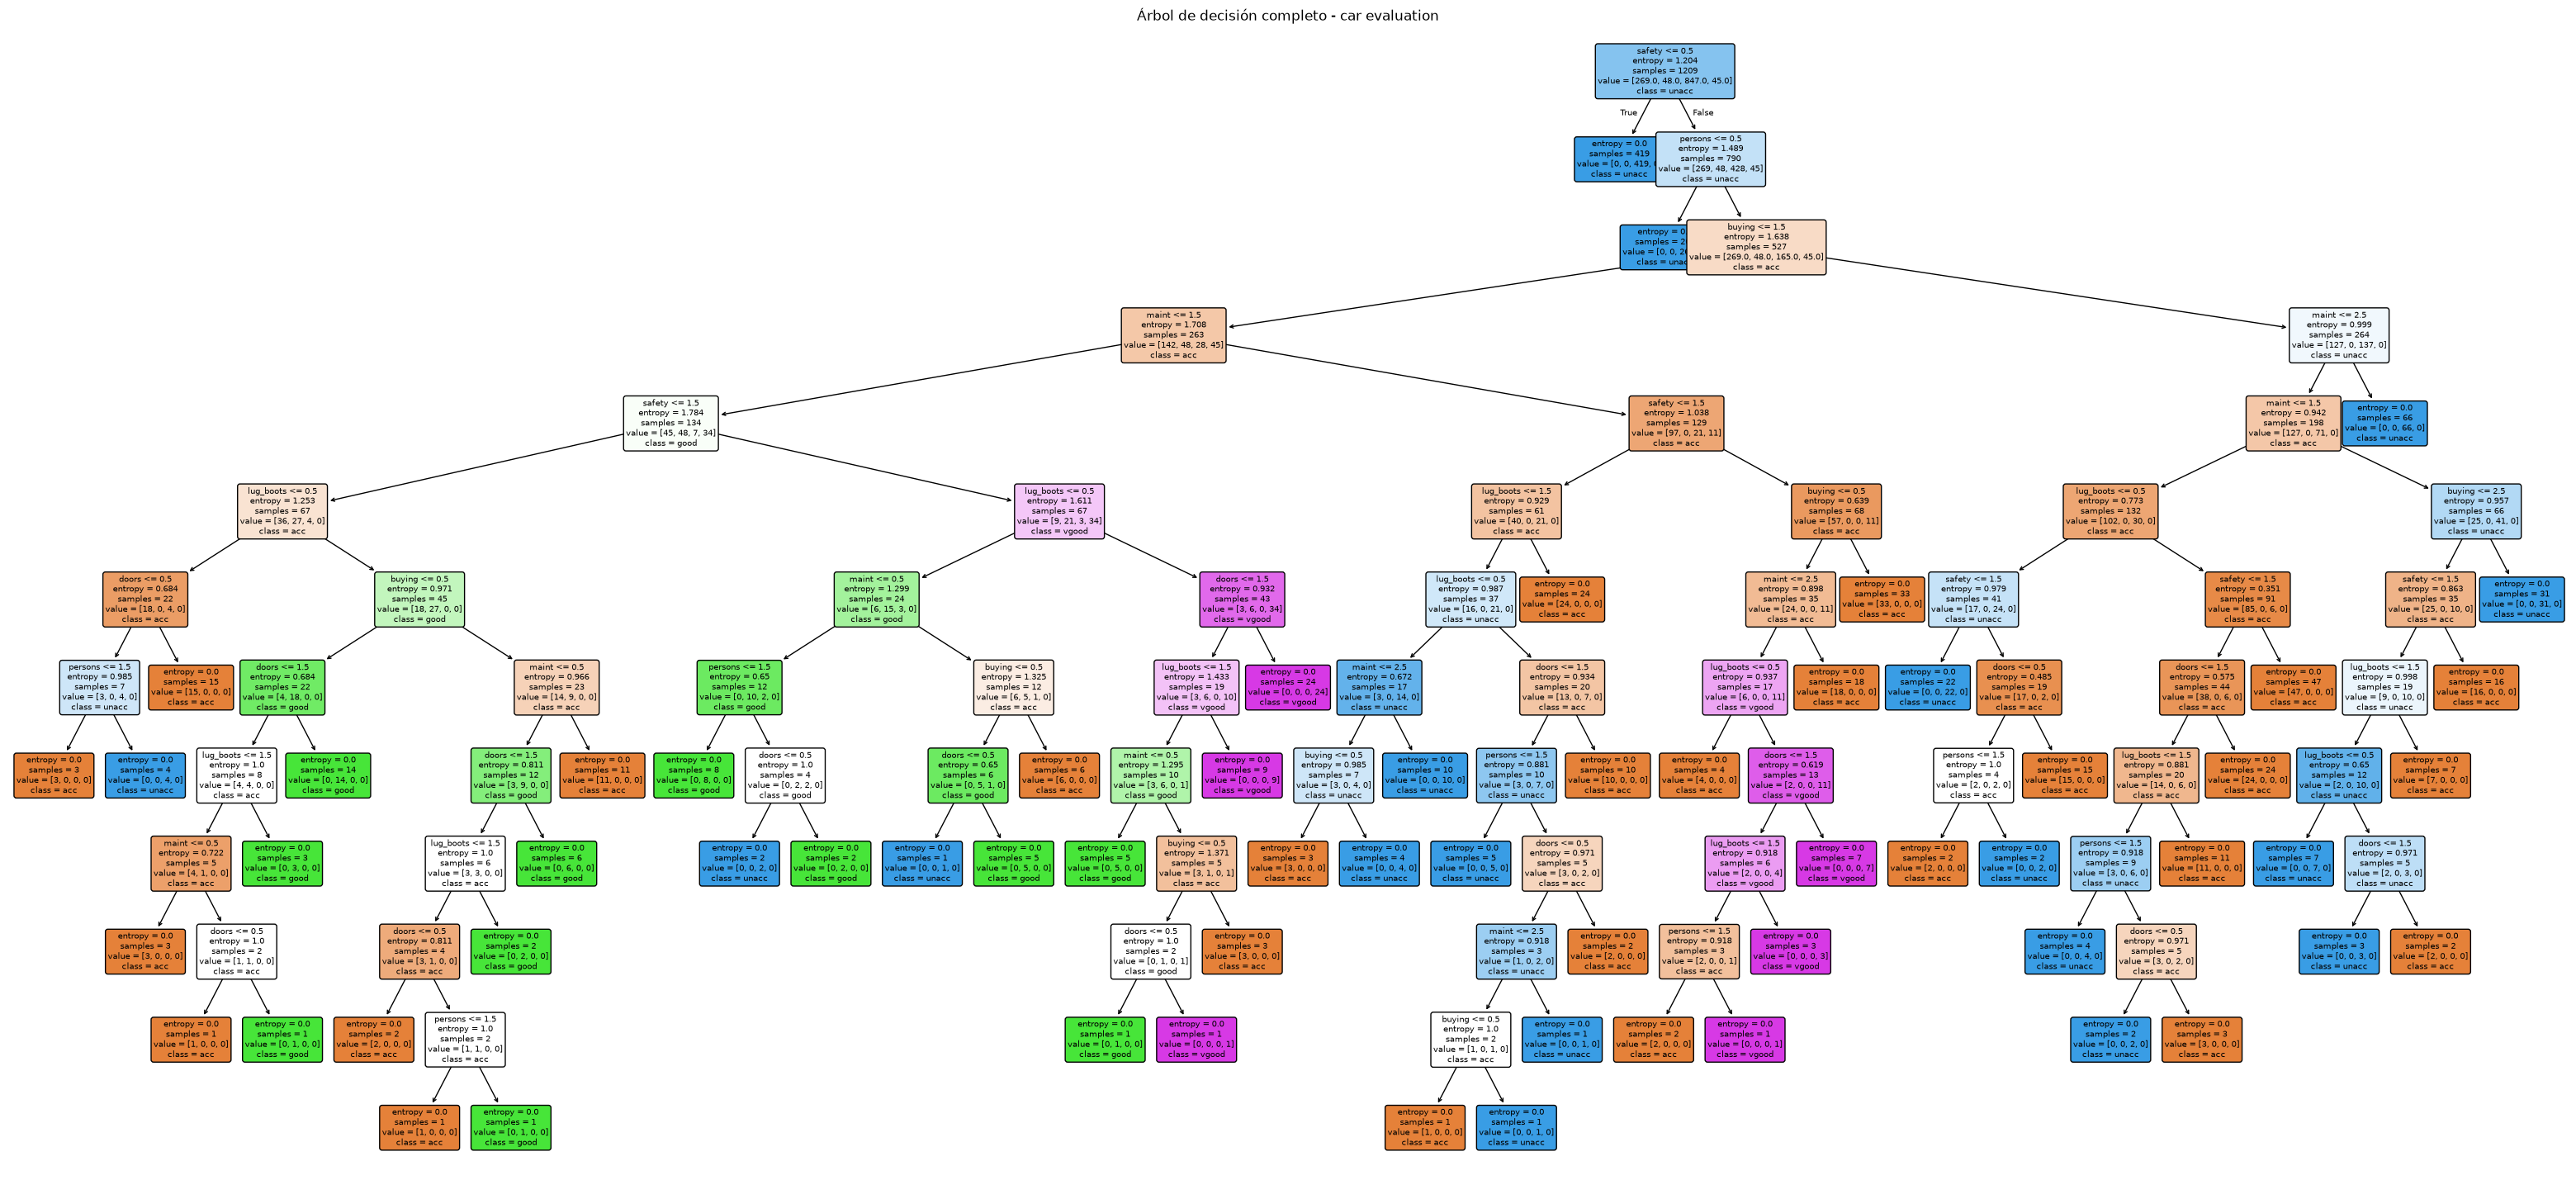

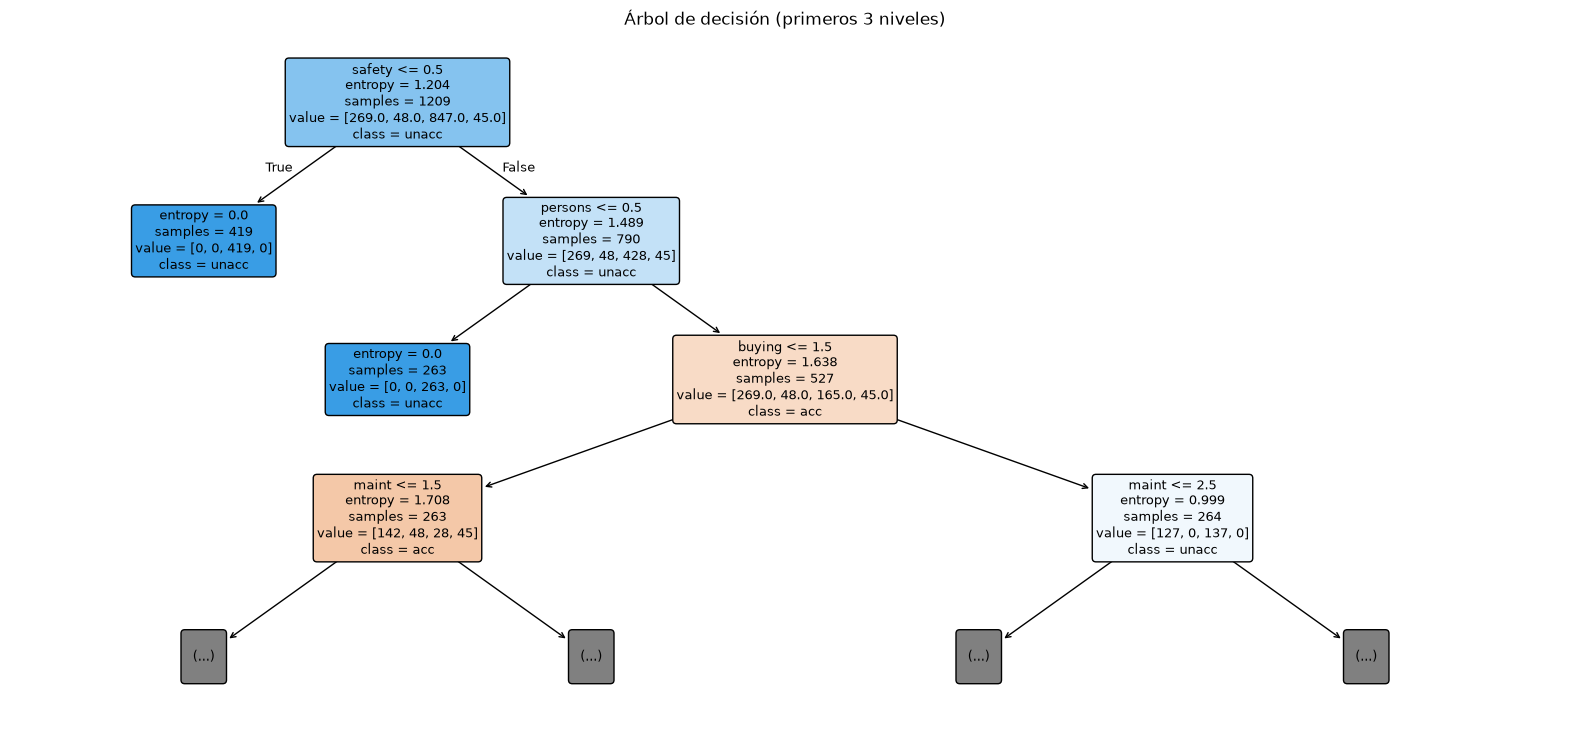

In [5]:
# Árbol completo
plt.figure(figsize=(40, 18))
plot_tree(model, feature_names=X.columns, class_names=model.classes_, filled=True, rounded=True, fontsize=7)
plt.title("Árbol de decisión completo - car evaluation")
plt.show()

# Primeros niveles, para poder leer los cortes principales
plt.figure(figsize=(20, 9))
plot_tree(model, feature_names=X.columns, class_names=model.classes_, filled=True, rounded=True, max_depth=3,
          fontsize=9)
plt.title("Árbol de decisión (primeros 3 niveles)")
plt.show()

=> Feature importance
safety       0.281
persons      0.234
buying       0.156
maint        0.153
lug_boots    0.120
doors        0.056
dtype: float64
=> Permutation importance
safety       0.243
persons      0.213
buying       0.179
maint        0.140
lug_boots    0.090
doors        0.028
dtype: float64


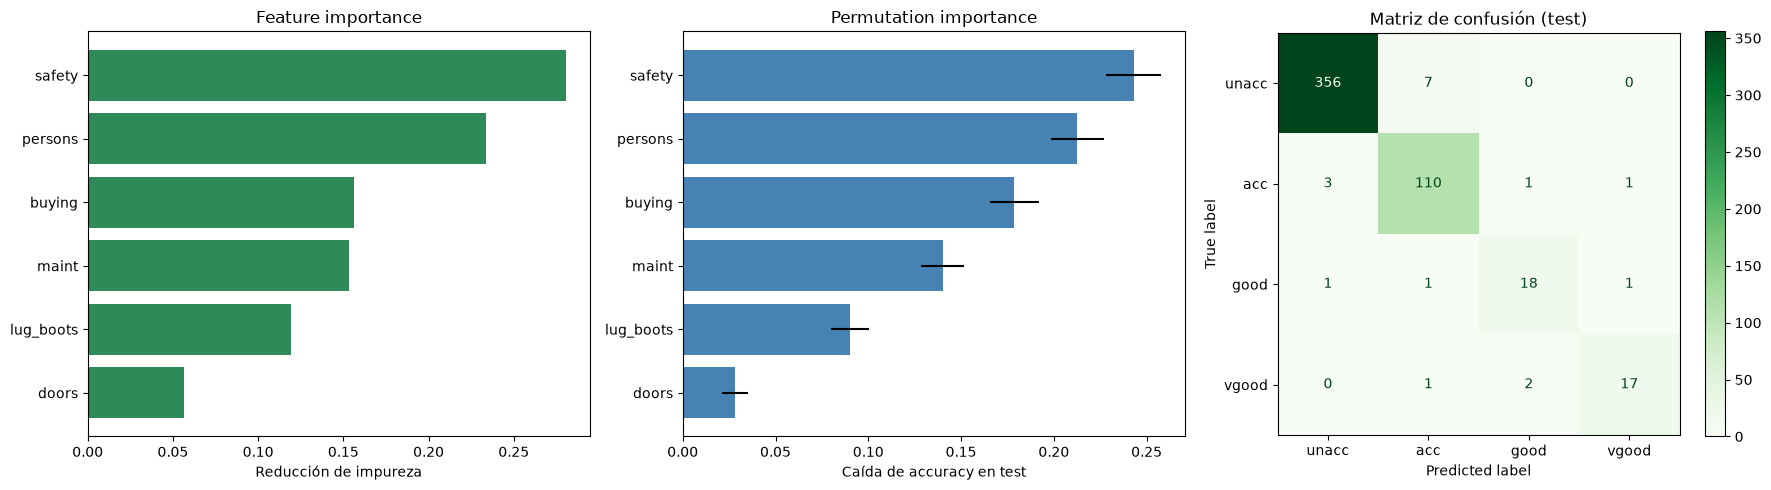

In [6]:
feature_imp = pd.Series(model.feature_importances_, index=X.columns).sort_values()

perm = permutation_importance(model, X_test, y_test, n_repeats=30, random_state=0, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=X.columns).sort_values()
perm_std = pd.Series(perm.importances_std, index=X.columns)[perm_imp.index]

print("=> Feature importance")
print(feature_imp.sort_values(ascending=False).round(3))
print("=> Permutation importance")
print(perm_imp.sort_values(ascending=False).round(3))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].barh(feature_imp.index, feature_imp.values, color="seagreen")
axes[0].set_xlabel("Reducción de impureza")
axes[0].set_title("Feature importance")

axes[1].barh(perm_imp.index, perm_imp.values, xerr=perm_std.values, color="steelblue")
axes[1].set_xlabel("Caída de accuracy en test")
axes[1].set_title("Permutation importance")

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_test, labels=["unacc", "acc", "good", "vgood"], ax=axes[2],
                                        cmap="Greens")
axes[2].set_title("Matriz de confusión (test)")

plt.tight_layout()
plt.show()

El árbol (criterio `entropy`, sin límite de profundidad: 12 niveles y 62 hojas) obtiene **98.1% en CV y 96.5% en prueba**. Las variables se codificaron con `OrdinalEncoder` respetando su orden (low < med < high…), así que los cortes del árbol se leen directo, por ejemplo `safety <= 0.5` significa seguridad baja → `unacc`.

- **Feature importance** y **permutation importance** dan el mismo orden: `safety` > `persons` > `buying` > `maint` > `lug_boots` > `doors`.
- Cuadra con el árbol: el primer corte es `safety` y el segundo `persons`. Si la seguridad es baja o el auto es para 2 personas, el auto es inaceptable sin importar lo demás.
- `doors` casi no aporta, la feature importance la sobrevalora un poco porque mide los cortes hechos en entrenamiento, mientras que la permutation importance mide el efecto real en datos de prueba.